# Chapitre 15 - Forêts aléatoires (2) : importance, proximités, analyse biais/variance

Ce second notebook couvre les sections 15.3.2 à 15.4 du livre :

1. l'**importance des variables** (critère de Gini et permutation OOB, figure 15.5) ;
2. les **graphiques de proximité** (figure 15.6) ;
3. le rôle des variables de bruit et de la profondeur des arbres (sur-apprentissage,
   figure 15.8) ;
4. l'**analyse de la variance et du biais** d'une forêt en fonction de $m$
   (figures 15.9 et 15.10) et le lien avec la régression ridge ;
5. la forêt vue comme un **plus proche voisin adaptatif** (figure 15.11).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch15_forets as rf
set_style()

## 1. Réglages par défaut (section 15.3)

Les inventeurs des forêts recommandent :

| tâche | $m$ par défaut | effectif minimal des feuilles $n_{\min}$ |
|---|---|---|
| classification | $\lfloor\sqrt p\rfloor$ | 1 |
| régression | $\lfloor p/3\rfloor$ | 5 |

Ce ne sont que des points de départ : $m$ et $n_{\min}$ sont des **paramètres de
réglage**, que l'on choisit par exemple en minimisant l'erreur OOB (voir l'exercice 15.6).

## 2. Importance des variables (section 15.3.2)

Deux mesures sont classiques.

**Importance « Gini ».** À chaque coupure d'un arbre, le critère (indice de Gini ou somme
des carrés) diminue d'une certaine quantité ; on attribue cette diminution à la variable
utilisée pour couper, et l'on somme sur tous les nœuds de tous les arbres. C'est la même
construction que pour le boosting (section 10.13).

**Importance par permutation OOB.** Pour l'arbre $b$, on mesure la précision sur ses
observations hors sac ; on **permute aléatoirement** les valeurs de la variable $j$ parmi
ces observations et l'on mesure à nouveau la précision. La baisse de précision, moyennée
sur les arbres, mesure l'importance de $X_j$.

> **Intuition.** Permuter la colonne $j$ conserve sa loi marginale mais détruit son lien
> avec $Y$ (et avec les autres variables) : c'est un peu comme mettre à zéro le
> coefficient de $X_j$ dans un modèle linéaire (exercice 15.7). Ce n'est **pas** la perte
> que l'on subirait en réajustant le modèle sans $X_j$ : d'autres variables corrélées
> pourraient alors la remplacer.

Ajustons notre forêt « maison » sur les données spam ($B=200$, $m=7$).

In [2]:
spam = datasets.load_spam()
Xtr, ytr, Xte, yte = rf.separer_spam(spam)
noms = np.array(rf.NOMS_SPAM)

t0 = time.time()
foret = rf.ForetAleatoire(B=200, m=7, nmin=1, classification=True, seed=0).fit(Xtr, ytr)
print("ajustement : %.0f s, erreur test : %.4f" % (time.time() - t0, np.mean(foret.predict(Xte) != yte)))

ajustement : 6 s, erreur test : 0.0469


In [3]:
t0 = time.time()
imp_gini = foret.importance_gini
imp_perm = rf.importance_permutation(foret, Xtr, ytr, seed=0)
imp_perm_pct = 100 * imp_perm / imp_perm.max()
print("permutations : %.0f s" % (time.time() - t0))
print("5 variables les plus importantes (Gini)        :", ", ".join(noms[np.argsort(-imp_gini)[:5]]))
print("5 variables les plus importantes (permutation) :", ", ".join(noms[np.argsort(-imp_perm)[:5]]))

permutations : 2 s
5 variables les plus importantes (Gini)        : !, remove, $, CAPAVE, free
5 variables les plus importantes (permutation) : !, remove, CAPMAX, hp, CAPTOT


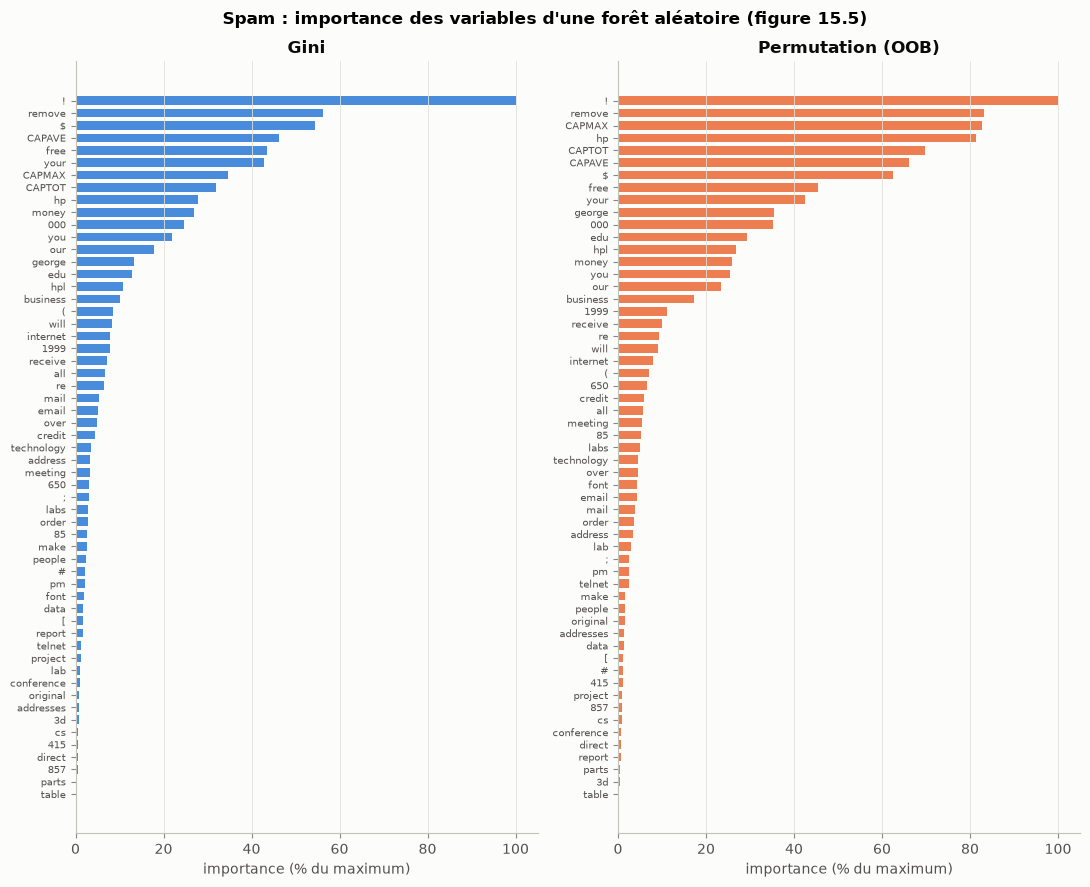

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 9))
for ax, imp, titre, c in [(axes[0], imp_gini, "Gini", BLUE), (axes[1], imp_perm_pct, "Permutation (OOB)", ORANGE)]:
    ordre = np.argsort(imp)
    ax.barh(np.arange(len(imp)), imp[ordre], color=c, alpha=0.85, height=0.7)
    ax.set_yticks(np.arange(len(imp)), noms[ordre], fontsize=7)
    ax.set_xlabel("importance (% du maximum)")
    ax.set_title(titre)
    ax.grid(axis="y", visible=False)
fig.suptitle("Spam : importance des variables d'une forêt aléatoire (figure 15.5)", fontweight="bold")
plt.tight_layout()
plt.show()

On retrouve les variables du livre en tête (« ! », « $ », « remove », « free », les
longueurs de suites de majuscules CAPAVE/CAPMAX/CAPTOT, « hp »…). Les deux classements
sont proches, mais la mesure par permutation **répartit l'importance plus uniformément**.
Comparons les rangs :

In [5]:
from scipy.stats import spearmanr
print("corrélation de Spearman entre les deux importances : %.3f" % spearmanr(imp_gini, imp_perm).correlation)
print("variables d'importance Gini < 5 %% : %d ; d'importance permutation < 5 %% : %d"
      % (np.sum(imp_gini < 5), np.sum(imp_perm_pct < 5)))

corrélation de Spearman entre les deux importances : 0.961
variables d'importance Gini < 5 % : 31 ; d'importance permutation < 5 % : 29


> **Remarque.** Contrairement au boosting (figure 10.6), la forêt n'ignore presque aucune
> variable : le tirage des $m$ candidates donne régulièrement leur chance à des variables
> faibles, qui sont alors choisies faute de mieux.

## 3. Graphiques de proximité (section 15.3.3)

Pendant la construction de la forêt, on accumule une matrice $N\times N$ de
**proximités** : pour chaque arbre, toute paire d'observations OOB qui tombent dans la
**même feuille** voit sa proximité augmenter de 1 (nous normalisons ensuite par le nombre
d'arbres où les deux observations sont OOB, pour obtenir une proximité
$P_{ii'}\in[0,1]$).

On représente ensuite ces proximités dans le plan par **positionnement multidimensionnel**
(MDS, section 14.8) appliqué aux dissimilarités $1-P_{ii'}$.

### Rappel : le MDS classique

Étant donné des dissimilarités $d_{ii'}$, on cherche des points $z_1,\dots,z_N\in\mathbb R^2$
dont les distances euclidiennes reproduisent au mieux les $d_{ii'}$. Si les $d_{ii'}$ sont
exactement des distances euclidiennes entre points centrés, la matrice des produits
scalaires $\mathbf B=(\langle z_i,z_{i'}\rangle)$ s'obtient par **double centrage** :
$\mathbf B=-\frac12\mathbf J\mathbf D^{(2)}\mathbf J$, où $\mathbf D^{(2)}=(d_{ii'}^2)$ et
$\mathbf J=\mathbf I-\frac1N\mathbf 1\mathbf 1^T$. On garde alors les deux premiers vecteurs
propres de $\mathbf B$, multipliés par la racine de leurs valeurs propres (fonction
`mds_classique`).

### Les données « mixture »

Comme dans le livre, nous utilisons les données simulées du chapitre 2 (200 points dans
le plan, deux classes). En dimension 2, $m=\lfloor\sqrt2\rfloor=1$.

In [ ]:
mix = datasets.load_mixture_example()
Xm, ym = mix["x"], mix["y"]
foret_mix = rf.ForetAleatoire(B=500, m=1, nmin=1, classification=True, seed=0).fit(Xm, ym)
Prox = rf.proximite(foret_mix.feuilles(Xm), foret_mix.dans_sac)
Zmds = rf.mds_classique(np.sqrt(1 - Prox), k=2)
print("proximité moyenne entre deux points de même classe : %.3f" % Prox[ym[:, None] == ym[None, :]].mean())
print("proximité moyenne entre deux points de classes différentes : %.3f" % Prox[ym[:, None] != ym[None, :]].mean())

Choisissons six points repères : pour chaque classe, le point le plus éloigné du centre
du graphique MDS (extrémité d'une « branche »), le point le plus proche du centre, et un
point à distance médiane.